# 국민연금 가입 사업장 데이터로 본 사업장 탈퇴(폐업) 조기 예측
### 데이터분석 기말대체 프로젝트 · 202444085 김철중

**문제:** 지금 국민연금에 가입되어 있는 사업장 중 **3개월 안에 탈퇴(폐업·휴업 등)할 사업장**을 미리 찾을 수 있을까?

- 데이터: 공공데이터포털 「국민연금공단_국민연금 가입 사업장 내역」 월별 CSV (2026-03, 04, 06, 07, 10월분)
- 기준월(T): **2026-07** → 정답(label): **2026-10** 파일에서 가입상태가 '탈퇴(2)'로 바뀌었는가
- 분석 흐름 (1주차 데이터과학 방법론): 데이터 수집 → 정제/병합 → EDA → 모델링 → 불균형 처리 → 튜닝 → 해석·제언

## 1. 라이브러리 불러오기

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time, os, sys

# 한글 폰트 (11주차: Matplotlib 한글 폰트 설정)
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False
sns.set_style('whitegrid', {'font.family': 'Malgun Gothic'})

os.makedirs('figures', exist_ok=True)
os.makedirs('results', exist_ok=True)
def save(name):
    plt.tight_layout()
    plt.savefig(f'figures/{name}.png', dpi=150, bbox_inches='tight')

## 2. 데이터 불러오기 및 정제 (3~5주차)
월별 파일은 약 59만 행, 22개 열이다. 같은 사업장을 여러 달에 걸쳐 연결해야 하므로
**사업자등록번호(앞 6자리) + 사업장명 + 법정동코드 + 업종코드**를 키로 사용한다.
키가 중복되는 행은 어느 사업장인지 구분할 수 없으므로 모두 제거한다 (3주차 `duplicated`).

In [2]:
cols = ['자료생성년월','사업장명','사업자번호','가입상태','우편번호','지번주소','도로명주소',
        '법정동코드','행정동코드','시도코드','시군구코드','읍면동코드','사업장형태','업종코드',
        '업종명','적용일자','재등록일자','탈퇴일자','가입자수','고지금액','신규취득자수','상실가입자수']
KEY = ['사업자번호','사업장명','법정동코드','업종코드']

def load_month(ym):
    df = pd.read_csv(f'data/raw/nps_{ym}.csv', encoding='cp949', names=cols, header=0, dtype=str)
    before = len(df)
    df = df[~df.duplicated(KEY, keep=False)]          # 키 중복 행 제거
    for c in ['가입자수','고지금액','신규취득자수','상실가입자수']:
        df[c] = pd.to_numeric(df[c])
    print(f'{ym}: {before:,}행 → 중복 제거 후 {len(df):,}행')
    return df

t = time.time()
base = load_month('202607')   # 기준월 T
m1   = load_month('202606')   # T-1
m3   = load_month('202604')   # T-3
m4   = load_month('202603')   # T-4
fut  = load_month('202610')   # T+3 (정답 확인용)
print(f'불러오기 {time.time()-t:.0f}초')

202607: 593,997행 → 중복 제거 후 593,706행


202606: 593,127행 → 중복 제거 후 592,846행


202604: 593,075행 → 중복 제거 후 592,788행


202603: 582,825행 → 중복 제거 후 582,571행


202610: 588,075행 → 중복 제거 후 587,812행
불러오기 38초


In [3]:
base.info()

<class 'pandas.DataFrame'>
Index: 593706 entries, 0 to 593996
Data columns (total 22 columns):
 #   Column  Non-Null Count   Dtype
---  ------  --------------   -----
 0   자료생성년월  593706 non-null  str  
 1   사업장명    593706 non-null  str  
 2   사업자번호   593706 non-null  str  
 3   가입상태    593706 non-null  str  
 4   우편번호    593706 non-null  str  
 5   지번주소    593706 non-null  str  
 6   도로명주소   571009 non-null  str  
 7   법정동코드   593706 non-null  str  
 8   행정동코드   593706 non-null  str  
 9   시도코드    593706 non-null  str  
 10  시군구코드   593706 non-null  str  
 11  읍면동코드   593706 non-null  str  
 12  사업장형태   593706 non-null  str  
 13  업종코드    593706 non-null  str  
 14  업종명     592989 non-null  str  
 15  적용일자    593703 non-null  str  
 16  재등록일자   21203 non-null   str  
 17  탈퇴일자    40029 non-null   str  
 18  가입자수    593706 non-null  int64
 19  고지금액    593706 non-null  int64
 20  신규취득자수  593706 non-null  int64
 21  상실가입자수  593706 non-null  int64
dtypes: int64(4), str(18)
memory usage: 2

In [4]:
base.isnull().sum()

자료생성년월         0
사업장명           0
사업자번호          0
가입상태           0
우편번호           0
지번주소           0
도로명주소      22697
법정동코드          0
행정동코드          0
시도코드           0
시군구코드          0
읍면동코드          0
사업장형태          0
업종코드           0
업종명          717
적용일자           3
재등록일자     572503
탈퇴일자      553677
가입자수           0
고지금액           0
신규취득자수         0
상실가입자수         0
dtype: int64

결측치는 `재등록일자`, `탈퇴일자`에만 있다. 이 두 값은 "해당 없음"이라는 의미이므로 삭제하지 않고
`재등록 여부` 같은 변수로 바꿔서 쓴다 (3주차 이상데이터 처리: ③ 변수화).

## 3. 데이터 병합과 정답(label) 만들기 (4~5주차 `merge`)
- 기준월(2026-07)에 **가입상태 = 1(등록)** 인 사업장만 대상으로 한다.
- 3개월 뒤(2026-10) 파일에서 가입상태가 **2(탈퇴)** 이면 `탈퇴=1`, 여전히 1이면 `탈퇴=0`.
- 2026-10 파일에서 아예 사라진 사업장은 탈퇴인지, 공개 범위(법인 3인·개인 10인 이상)에서 빠진 것인지,
  사업장명 변경인지 알 수 없으므로 분석에서 제외한다.

In [5]:
base = base[base['가입상태'] == '1']

def lag_cols(df, tag):
    out = df[KEY + ['가입자수','고지금액','신규취득자수','상실가입자수']].copy()
    return out.rename(columns={c: c + tag for c in ['가입자수','고지금액','신규취득자수','상실가입자수']})

df = base.merge(lag_cols(m1, '_m1'), on=KEY, how='left')
df = df.merge(lag_cols(m3, '_m3'), on=KEY, how='left')
df = df.merge(lag_cols(m4, '_m4'), on=KEY, how='left')
df = df.merge(fut[KEY + ['가입상태']].rename(columns={'가입상태': '가입상태_3개월후'}), on=KEY, how='left')

print('기준월 등록 사업장:', f'{len(df):,}')
print(df['가입상태_3개월후'].fillna('사라짐').value_counts())

df = df[df['가입상태_3개월후'].notna()].copy()
df['탈퇴'] = (df['가입상태_3개월후'] == '2').astype(int)
print('\n분석 대상:', f'{len(df):,}', '/ 탈퇴 비율:', round(df['탈퇴'].mean() * 100, 3), '%')

기준월 등록 사업장: 553,676
가입상태_3개월후
1      511508
사라짐     40135
2        2033
Name: count, dtype: int64



분석 대상: 513,541 / 탈퇴 비율: 0.396 %


## 4. 파생변수 만들기 (5주차 함수 매핑·연산)
| 변수 | 의미 |
|---|---|
| 1인당고지금액 | 고지금액 ÷ 가입자수 (급여 수준의 대리 지표) |
| 상실률 / 취득률 | 이번 달 상실(퇴사)·취득(입사) 인원 ÷ 가입자수 |
| 업력 | 2026-07-31 − 적용일자 (년) |
| 인원증감률_1/3/4개월 | (현재 가입자수 − n개월 전 가입자수) ÷ n개월 전 가입자수 |
| 고지금액증감률_3개월 | 3개월 동안 고지금액 변화율 (급여 축소·휴직 신호) |
| 최근상실자합 | 이번 달 + 지난 달 상실자 수 |
| 신규진입 | 3개월 전 파일에 없던 사업장 |

In [6]:
df['1인당고지금액'] = np.where(df['가입자수'] > 0, df['고지금액'] / df['가입자수'], 0)
df['상실률'] = np.where(df['가입자수'] > 0, df['상실가입자수'] / df['가입자수'], 0)
df['취득률'] = np.where(df['가입자수'] > 0, df['신규취득자수'] / df['가입자수'], 0)
df['업력'] = (pd.Timestamp('2026-07-31') - pd.to_datetime(df['적용일자'], errors='coerce')).dt.days / 365.25
df['재등록여부'] = df['재등록일자'].notna().astype(int)
df['법인여부'] = (df['사업장형태'] == '1').astype(int)
df['신규진입'] = df['가입자수_m3'].isna().astype(int)

def rate(now, before):
    return (now - before) / before.replace(0, np.nan)

df['인원증감률_1개월'] = rate(df['가입자수'], df['가입자수_m1'])
df['인원증감률_3개월'] = rate(df['가입자수'], df['가입자수_m3'])
df['인원증감률_4개월'] = rate(df['가입자수'], df['가입자수_m4'])
df['고지금액증감률_3개월'] = rate(df['고지금액'], df['고지금액_m3'])
df['최근상실자합'] = df['상실가입자수'] + df['상실가입자수_m1'].fillna(0)

df['시도코드'] = df['시도코드'].astype(int)
df['업종대분류'] = df['업종코드'].str[:2].astype(int)

FEATURES = ['가입자수','1인당고지금액','신규취득자수','상실가입자수','상실률','취득률','업력',
            '재등록여부','법인여부','신규진입','인원증감률_1개월','인원증감률_3개월',
            '인원증감률_4개월','고지금액증감률_3개월','최근상실자합','시도코드','업종대분류']

X = df[FEATURES].replace([np.inf, -np.inf], np.nan).fillna(0)   # 비교 대상이 없으면 변화 0으로 처리
y = df['탈퇴']
X.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
가입자수,513541.0,21.67,270.50,0.0,4.00,7.00,14.00,125720.00
1인당고지금액,513541.0,316095.30,98829.37,0.0,246943.33,310382.50,377030.00,626040.00
신규취득자수,513541.0,0.85,9.00,0.0,0.00,0.00,1.00,2209.00
상실가입자수,513541.0,0.64,7.64,0.0,0.00,0.00,0.00,2044.00
상실률,513541.0,0.03,0.08,0.0,0.00,0.00,0.00,1.00
취득률,513541.0,0.04,0.13,0.0,0.00,0.00,0.02,1.00
업력,513541.0,12.12,9.43,0.0,4.51,9.83,18.25,38.58
재등록여부,513541.0,0.02,0.15,0.0,0.00,0.00,0.00,1.00
법인여부,513541.0,0.92,0.27,0.0,1.00,1.00,1.00,1.00
신규진입,513541.0,0.14,0.34,0.0,0.00,0.00,0.00,1.00


## 5. 탐색적 데이터 분석 EDA (7주차: 관찰 → 요약통계 → 시각화)

### 5-1. 클래스 불균형과 '정확도의 함정' (1주차 FDS 예시)

탈퇴
0    511508
1      2033
Name: count, dtype: int64


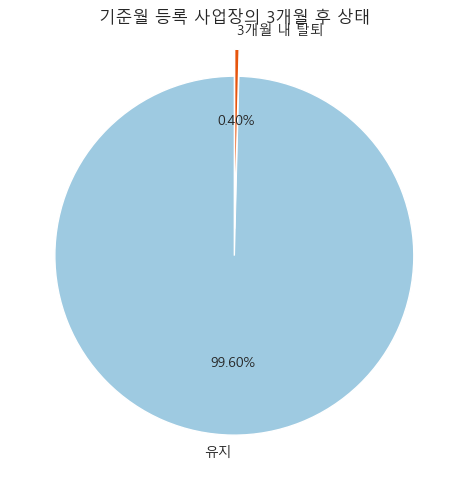

전부 0으로 예측했을 때 정확도: 99.6 %  → 하지만 탈퇴 사업장은 하나도 못 찾음


In [7]:
print(y.value_counts())
plt.figure(figsize=(5, 5))
plt.pie(y.value_counts(), labels=['유지', '3개월 내 탈퇴'], autopct='%.2f%%',
        colors=['#9ecae1', '#e6550d'], startangle=90, explode=[0, 0.15])
plt.title('기준월 등록 사업장의 3개월 후 상태')
save('01_class_ratio')
plt.show()

# 모든 사업장을 '유지'라고 찍기만 해도 정확도는?
print('전부 0으로 예측했을 때 정확도:', round((y == 0).mean() * 100, 2), '%  → 하지만 탈퇴 사업장은 하나도 못 찾음')

탈퇴 비율이 약 0.4%밖에 안 되므로, 아무것도 학습하지 않고 전부 "유지"라고 해도 정확도가 99.6%가 나온다.
그래서 이 프로젝트는 **정확도 대신 Precision, Recall, F1, PR-AUC(Average Precision)** 를 주 평가지표로 쓴다.

### 5-2. 규모·업력별 탈퇴율

            mean    size
규모구간                    
0명      0.774194      93
1~4명    0.006209  150743
5~9명    0.003856  157173
10~29명  0.002349  153686
30~99명  0.001351   39217
100명+   0.000396   12629 
             mean    size
업력구간                    
1년 미만   0.029769   31879
1~3년    0.008214   58555
3~5년    0.003260   51226
5~10년   0.002157  118666
10~20년  0.000873  143151
20년+    0.000500  110061


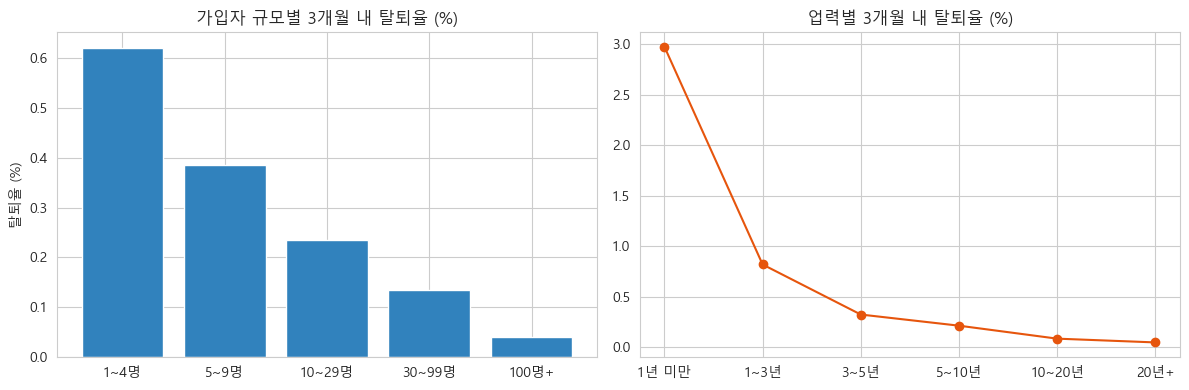

※ 가입자 0명인 등록 사업장의 탈퇴율: 77.4 % (n = 93 )


In [8]:
df['규모구간'] = pd.cut(df['가입자수'], bins=[-1, 0, 4, 9, 29, 99, 10**7],
                    labels=['0명', '1~4명', '5~9명', '10~29명', '30~99명', '100명+'])
df['업력구간'] = pd.cut(df['업력'], bins=[-1, 1, 3, 5, 10, 20, 100],
                    labels=['1년 미만', '1~3년', '3~5년', '5~10년', '10~20년', '20년+'])

size_rate = df.groupby('규모구간')['탈퇴'].agg(['mean', 'size'])
age_rate = df.groupby('업력구간')['탈퇴'].agg(['mean', 'size'])
print(size_rate, '\n', age_rate)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(size_rate.index.astype(str)[1:], size_rate['mean'][1:] * 100, color='#3182bd')
ax[0].set_title('가입자 규모별 3개월 내 탈퇴율 (%)')
ax[0].set_ylabel('탈퇴율 (%)')
ax[1].plot(age_rate.index.astype(str), age_rate['mean'] * 100, marker='o', color='#e6550d')
ax[1].set_title('업력별 3개월 내 탈퇴율 (%)')
save('02_size_age_rate')
plt.show()
print('※ 가입자 0명인 등록 사업장의 탈퇴율:', round(size_rate.loc['0명', 'mean'] * 100, 1), '% (n =', size_rate.loc['0명', 'size'], ')')

### 5-3. 업종별 탈퇴율 (사업장 1,000곳 이상 업종)

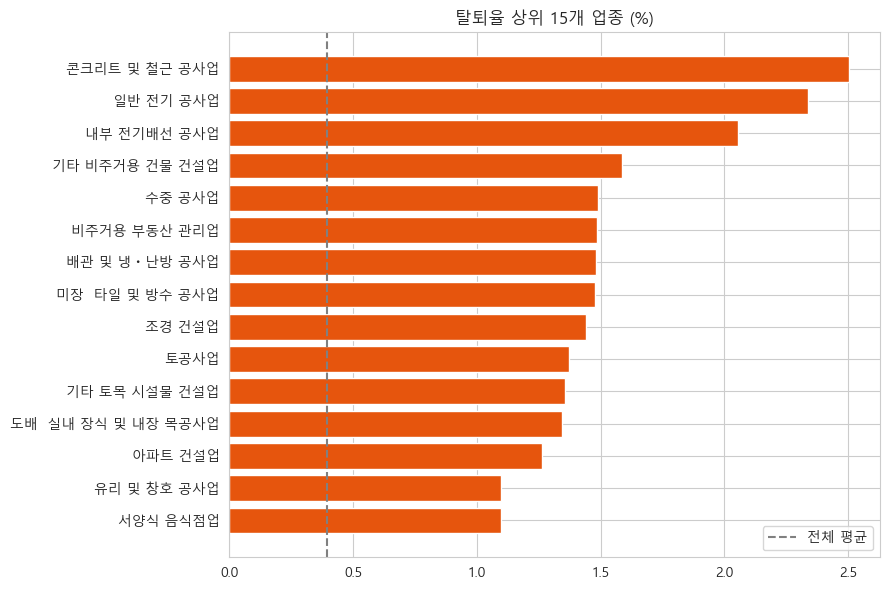

,mean,size
업종명,,
콘크리트 및 철근 공사업,0.025041,1837
일반 전기 공사업,0.023369,2054
내부 전기배선 공사업,0.020572,1118
기타 비주거용 건물 건설업,0.015860,1198
수중 공사업,0.014883,1747
비주거용 부동산 관리업,0.014838,4111
배관 및 냉ㆍ난방 공사업,0.014816,11474
미장 타일 및 방수 공사업,0.014769,5823
조경 건설업,0.014423,1664


In [9]:
ind = df.groupby('업종명')['탈퇴'].agg(['mean', 'size'])
ind = ind[ind['size'] >= 1000].sort_values('mean', ascending=False)
top = ind.head(15).sort_values('mean')

plt.figure(figsize=(9, 6))
plt.barh(top.index, top['mean'] * 100, color='#e6550d')
plt.axvline(df['탈퇴'].mean() * 100, color='gray', linestyle='--', label='전체 평균')
plt.title('탈퇴율 상위 15개 업종 (%)')
plt.legend()
save('03_industry_top15')
plt.show()
ind.head(15)

In [10]:
# 탈퇴율 상위 업종이 대부분 건설·공사업 → 건설업 비중 확인
df['건설업'] = df['업종명'].fillna('').str.contains('공사|건설').astype(int)
print('전체 사업장 중 건설·공사업 비중:', round(df['건설업'].mean() * 100, 1), '%')
print('탈퇴 사업장 중 건설·공사업 비중:', round(df.loc[df['탈퇴'] == 1, '건설업'].mean() * 100, 1), '%')
print('신규진입(3개월 내 등록) 사업장의 탈퇴율:', round(df.loc[df['신규진입'] == 1, '탈퇴'].mean() * 100, 2), '%',
      '/ 기존 사업장:', round(df.loc[df['신규진입'] == 0, '탈퇴'].mean() * 100, 2), '%')

전체 사업장 중 건설·공사업 비중: 13.9 %
탈퇴 사업장 중 건설·공사업 비중: 49.0 %
신규진입(3개월 내 등록) 사업장의 탈퇴율: 1.31 % / 기존 사업장: 0.25 %


건설·공사업은 공사 현장마다 사업장을 따로 등록했다가 공사가 끝나면 탈퇴하는 경우가 많다.
따라서 이 데이터의 '탈퇴'는 **폐업뿐 아니라 현장 종료·휴업·이전**까지 포함한다는 점을 해석할 때 주의해야 한다.

### 5-4. 지역별 탈퇴율

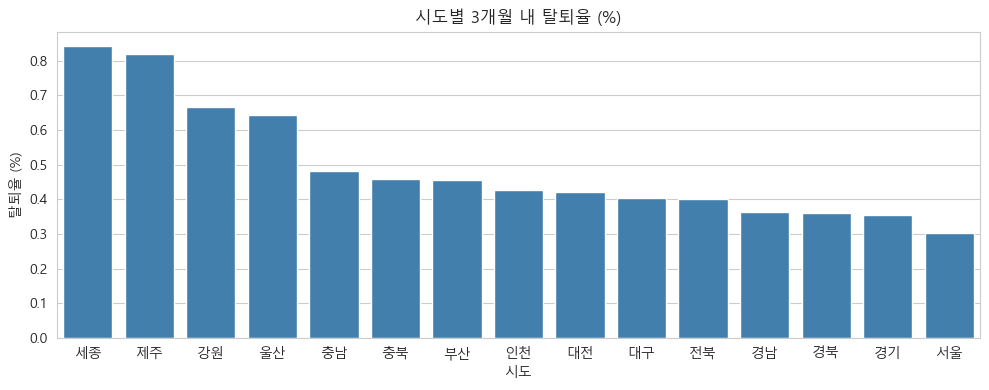

In [11]:
sido_name = {11:'서울', 26:'부산', 27:'대구', 28:'인천', 29:'광주', 30:'대전', 31:'울산', 36:'세종',
             41:'경기', 42:'강원', 43:'충북', 44:'충남', 45:'전북', 46:'전남', 47:'경북', 48:'경남',
             50:'제주', 51:'강원', 52:'전북'}
df['시도'] = df['시도코드'].map(sido_name)
sido = df.groupby('시도')['탈퇴'].agg(['mean', 'size'])
sido = sido[sido['size'] >= 1000].sort_values('mean', ascending=False)

plt.figure(figsize=(10, 4))
sns.barplot(x=sido.index, y=sido['mean'] * 100, color='#3182bd')
plt.title('시도별 3개월 내 탈퇴율 (%)')
plt.ylabel('탈퇴율 (%)')
save('04_sido_rate')
plt.show()

### 5-5. 탈퇴 여부에 따른 변수 분포 (12주차 seaborn boxplot)

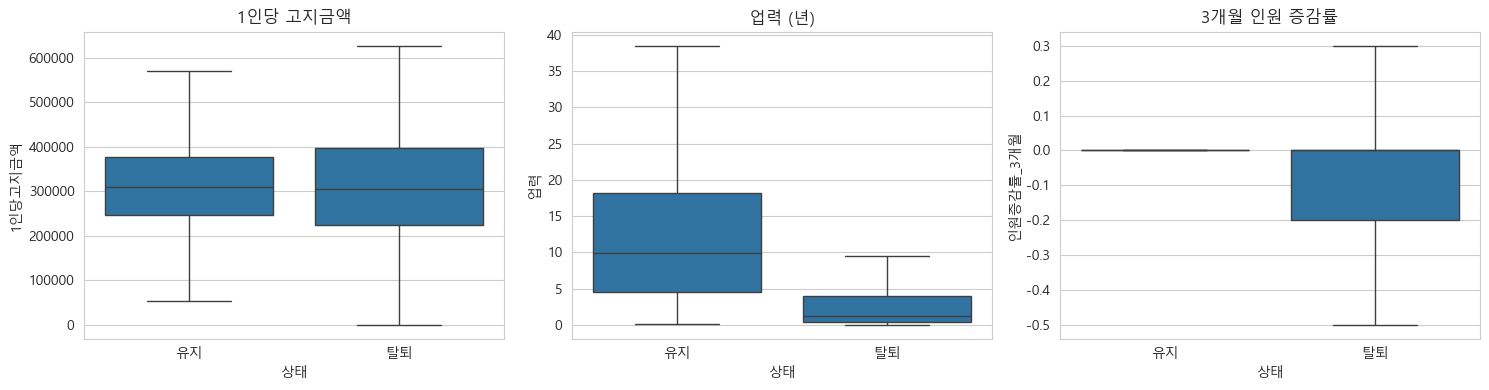

,가입자수,1인당고지금액,업력,상실률,인원증감률_3개월,고지금액증감률_3개월
탈퇴,,,,,,
0,7.0,310405.000000,9.880903,0.0,0.0,0.030268
1,5.0,305386.666667,1.163587,0.0,0.0,0.000000


In [12]:
sample = df.sample(50000, random_state=42)
sample = pd.concat([sample, df[df['탈퇴'] == 1]]).drop_duplicates()
sample['상태'] = sample['탈퇴'].map({0: '유지', 1: '탈퇴'})

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(data=sample, x='상태', y='1인당고지금액', ax=ax[0], showfliers=False)
ax[0].set_title('1인당 고지금액')
sns.boxplot(data=sample, x='상태', y='업력', ax=ax[1], showfliers=False)
ax[1].set_title('업력 (년)')
sns.boxplot(data=sample, x='상태', y=sample['인원증감률_3개월'].clip(-1, 1), ax=ax[2], showfliers=False)
ax[2].set_title('3개월 인원 증감률')
save('05_boxplots')
plt.show()

df.groupby('탈퇴')[['가입자수','1인당고지금액','업력','상실률','인원증감률_3개월','고지금액증감률_3개월']].median()

### 5-6. 상관관계 히트맵 (7주차·12주차)

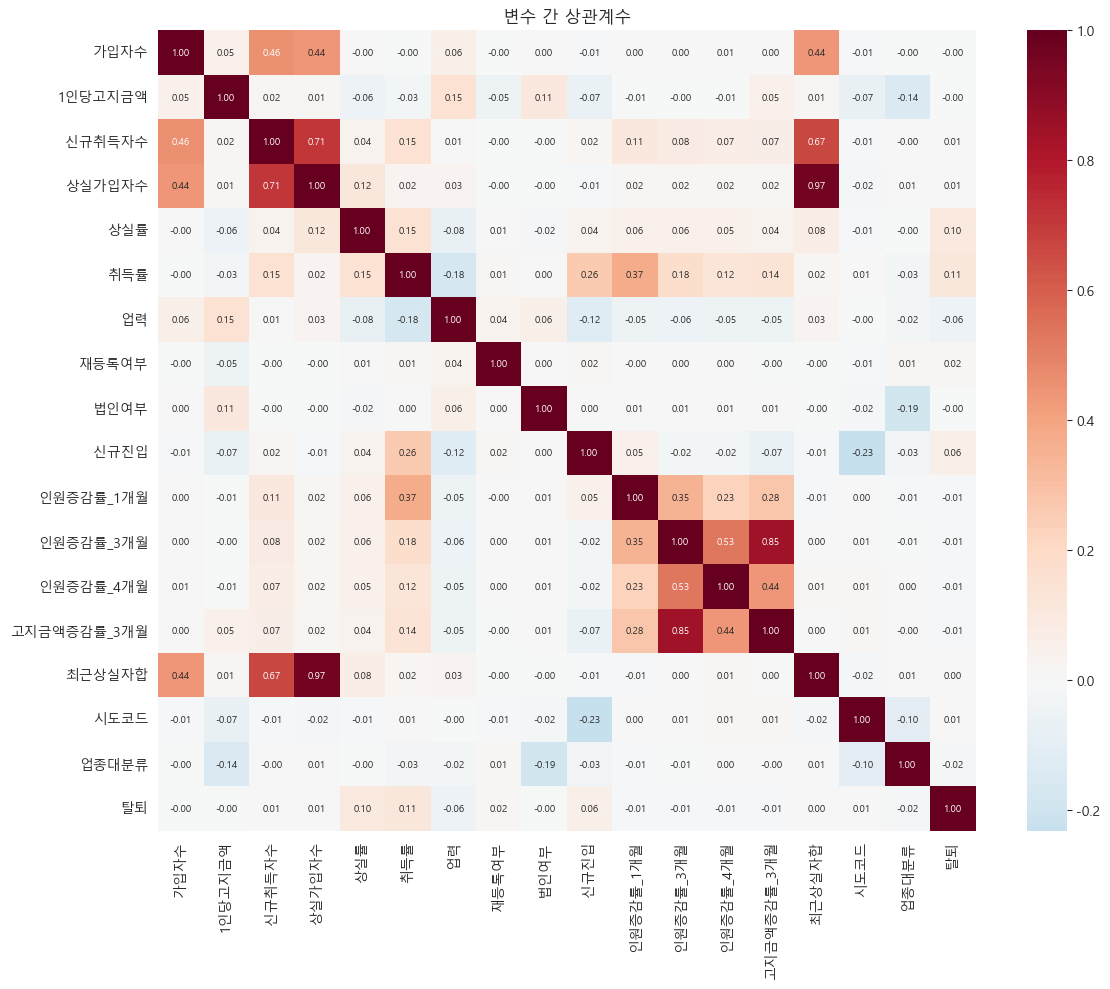

업력            -0.058017
업종대분류         -0.017517
고지금액증감률_3개월   -0.013959
인원증감률_3개월     -0.009698
인원증감률_4개월     -0.008122
인원증감률_1개월     -0.005712
1인당고지금액       -0.004095
가입자수          -0.003106
법인여부          -0.002334
최근상실자합         0.002037
상실가입자수         0.005271
시도코드           0.005323
신규취득자수         0.006716
재등록여부          0.015131
신규진입           0.058089
상실률            0.098185
취득률            0.110093
Name: 탈퇴, dtype: float64

In [13]:
corr = pd.concat([X, y], axis=1).corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, annot_kws={'size': 7})
plt.title('변수 간 상관계수')
save('06_corr_heatmap')
plt.show()
corr['탈퇴'].drop('탈퇴').sort_values()

탈퇴와 단순 선형 상관이 큰 변수는 거의 없다(|r| < 0.1). 즉 하나의 변수로 설명되는 문제가 아니라
**여러 신호의 조합**을 봐야 하는 문제이므로, 비선형 관계를 잡는 트리 기반 앙상블 모델이 유리할 것으로 예상된다.

## 6. 학습/테스트 분리 (6주차)
탈퇴 비율을 유지하도록 `stratify=y` 로 8:2 분할한다. 테스트셋은 마지막 평가 전까지 쓰지 않는다.

In [14]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(X_train.shape, X_test.shape, '/ 학습 탈퇴 수:', y_train.sum(), '/ 테스트 탈퇴 수:', y_test.sum())

(410832, 17) (102709, 17) / 학습 탈퇴 수: 1626 / 테스트 탈퇴 수: 407


## 7. 모델 비교: 층화 5-겹 교차검증 (7·9·10주차)
교안에서 배운 분류 알고리즘을 같은 조건에서 비교한다. 시간 절약을 위해 학습셋에서
탈퇴 비율을 유지한 15만 행을 뽑아 교차검증한다.
SVM은 15만 행에서 학습 시간이 지나치게 길어 제외했다.

In [15]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, VotingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

X_cv, _, y_cv, _ = train_test_split(X_train, y_train, train_size=150000, stratify=y_train, random_state=42)

models = {
    'LogisticRegression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    'DecisionTree': DecisionTreeClassifier(max_depth=8, random_state=42),
    'RandomForest': RandomForestClassifier(n_estimators=100, min_samples_leaf=3, n_jobs=-1, random_state=42),
    'AdaBoost': AdaBoostClassifier(random_state=42),
    'XGBoost': XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.05, n_jobs=-1, random_state=42),
    'LightGBM': LGBMClassifier(n_estimators=300, learning_rate=0.05, verbose=-1, random_state=42),
}
models['Voting(soft)'] = VotingClassifier(
    estimators=[('rf', models['RandomForest']), ('xgb', models['XGBoost']), ('lgbm', models['LightGBM'])],
    voting='soft')

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'average_precision']

rows = []
for name, model in models.items():
    t = time.time()
    s = cross_validate(model, X_cv, y_cv, cv=skf, scoring=scoring, n_jobs=1)
    row = {'model': name}
    for m in scoring:
        row[m] = s['test_' + m].mean()
    row['PR-AUC std'] = s['test_average_precision'].std()
    row['time(s)'] = time.time() - t
    rows.append(row)
    print(f'{name:20s} PR-AUC={row["average_precision"]:.4f}  ROC-AUC={row["roc_auc"]:.4f}  ({row["time(s)"]:.0f}s)')

cv_result = pd.DataFrame(rows).set_index('model').sort_values('average_precision', ascending=False)
cv_result.to_csv('results/model_cv_result.csv', encoding='utf-8-sig')
cv_result.round(4)

LogisticRegression   PR-AUC=0.0908  ROC-AUC=0.8608  (1s)


DecisionTree         PR-AUC=0.0984  ROC-AUC=0.7610  (3s)


RandomForest         PR-AUC=0.1829  ROC-AUC=0.8456  (52s)


AdaBoost             PR-AUC=0.0981  ROC-AUC=0.8739  (38s)


XGBoost              PR-AUC=0.1720  ROC-AUC=0.8905  (9s)


LightGBM             PR-AUC=0.1518  ROC-AUC=0.8759  (17s)


Voting(soft)         PR-AUC=0.1889  ROC-AUC=0.8860  (83s)


,accuracy,precision,recall,f1,roc_auc,average_precision,PR-AUC std,time(s)
model,,,,,,,,
Voting(soft),0.9961,0.5923,0.0640,0.1147,0.8860,0.1889,0.0199,83.0087
RandomForest,0.9961,0.6812,0.0555,0.1020,0.8456,0.1829,0.0177,52.2588
XGBoost,0.9962,0.7735,0.0572,0.1057,0.8905,0.1720,0.0248,9.3523
LightGBM,0.9958,0.3909,0.0926,0.1490,0.8759,0.1518,0.0222,16.8997
DecisionTree,0.9958,0.3838,0.0976,0.1550,0.7610,0.0984,0.0055,3.2550
AdaBoost,0.9961,0.5500,0.0084,0.0165,0.8739,0.0981,0.0334,37.8784
LogisticRegression,0.9959,0.3020,0.0252,0.0466,0.8608,0.0908,0.0193,1.2495


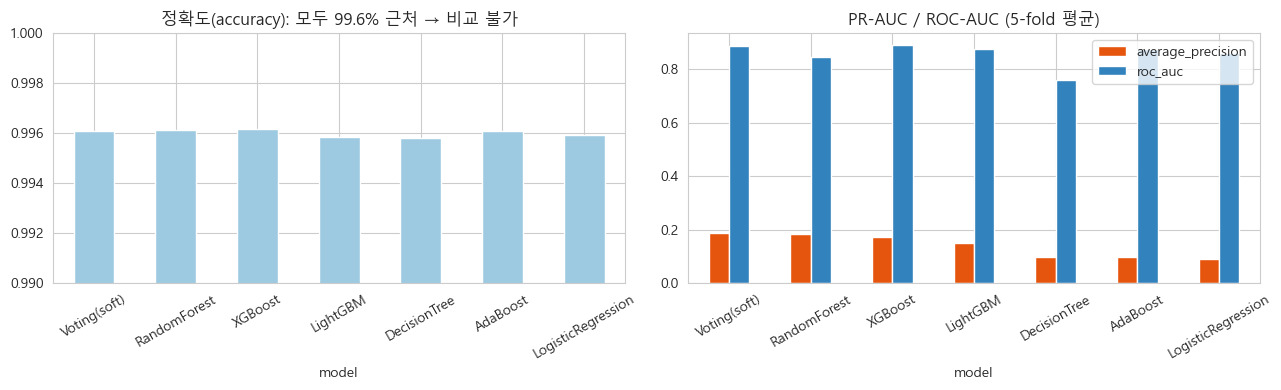

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
cv_result['accuracy'].plot(kind='bar', ax=ax[0], color='#9ecae1', ylim=(0.99, 1.0))
ax[0].set_title('정확도(accuracy): 모두 99.6% 근처 → 비교 불가')
cv_result[['average_precision', 'roc_auc']].plot(kind='bar', ax=ax[1], color=['#e6550d', '#3182bd'])
ax[1].set_title('PR-AUC / ROC-AUC (5-fold 평균)')
for a in ax: a.tick_params(axis='x', rotation=30)
save('07_model_compare')
plt.show()

정확도로는 모든 모델이 99.6%대로 차이가 없다. 확률 순위를 평가하는 PR-AUC·ROC-AUC로 보면 차이가 드러난다.
PR-AUC 기준으로 **Voting(soft) ≈ RandomForest > XGBoost > LightGBM** 순이며, 무작위로 고를 때의 기준선(탈퇴 비율 0.004)보다
약 45배 높다. 단일 결정트리와 로지스틱 회귀는 앙상블보다 크게 낮다.
또 임계값 0.5에서는 대부분 모델의 Recall이 매우 낮다. 소수 클래스(탈퇴)를 거의 "유지"로 예측해 버리는
**다수결 편향** 때문이며, 다음 단계에서 불균형 처리로 이를 완화한다.

## 8. 불균형 처리 기법 비교: SMOTE · ADASYN · FI-SMOTE
소수 클래스를 늘리는 오버샘플링은 **학습셋에만** 적용하고, 테스트셋은 원본 그대로 평가한다
(테스트셋까지 늘리면 정보 누수가 생김).
- `class_weight`: 샘플을 만들지 않고 소수 클래스 오차에 가중치를 주는 방법
- SMOTE / ADASYN: imbalanced-learn 라이브러리 (교안 외 기법)
- **FI-SMOTE**: 본인이 1학기에 제안한 기법. 특성 중요도가 높은 변수는 원본 근처에서, 낮은 변수는 자유롭게 보간
- 모든 오버샘플링은 소수 클래스를 다수 클래스의 10%까지 늘린다 (`sampling_strategy=0.1`)

In [17]:
from imblearn.over_sampling import SMOTE, ADASYN
from sklearn.metrics import (f1_score, precision_score, recall_score, roc_auc_score,
                             average_precision_score, matthews_corrcoef)
sys.path.append('src')
from fi_smote import fi_smote_resample

def recall_at_top(y_true, prob, pct):
    # 위험 점수 상위 pct% 사업장만 점검했을 때 실제 탈퇴 사업장 중 몇 %를 찾는가
    n = int(len(prob) * pct / 100)
    top = np.argsort(prob)[::-1][:n]
    return np.asarray(y_true)[top].sum() / np.asarray(y_true).sum()

def evaluate(y_true, prob, th=0.5):
    pred = (prob >= th).astype(int)
    return {'PR-AUC': average_precision_score(y_true, prob), 'ROC-AUC': roc_auc_score(y_true, prob),
            'Precision': precision_score(y_true, pred, zero_division=0), 'Recall': recall_score(y_true, pred),
            'F1': f1_score(y_true, pred), 'MCC': matthews_corrcoef(y_true, pred),
            'Recall@상위5%': recall_at_top(y_true, prob, 5)}

samplers = {
    '없음': None,
    'class_weight': 'weight',
    'SMOTE': SMOTE(sampling_strategy=0.1, random_state=42),
    'ADASYN': ADASYN(sampling_strategy=0.1, random_state=42),
    'FI-SMOTE': 'fi',
}

def make_model(name, weight=False):
    if name == 'LightGBM':
        return LGBMClassifier(n_estimators=300, learning_rate=0.05, verbose=-1, random_state=42,
                              class_weight='balanced' if weight else None)
    return RandomForestClassifier(n_estimators=100, min_samples_leaf=3, n_jobs=-1, random_state=42,
                                  class_weight='balanced_subsample' if weight else None)

res_rows = []
for s_name, sampler in samplers.items():
    t = time.time()
    if sampler is None or sampler == 'weight':
        Xr, yr = X_train, y_train
    elif sampler == 'fi':
        Xr, yr = fi_smote_resample(X_train, y_train, sampling_strategy=0.1, random_state=42)
    else:
        Xr, yr = sampler.fit_resample(X_train, y_train)
    for m_name in ['LightGBM', 'RandomForest']:
        model = make_model(m_name, weight=(sampler == 'weight'))
        model.fit(Xr, yr)
        prob = model.predict_proba(X_test)[:, 1]
        row = {'모델': m_name, '불균형처리': s_name, '학습행수': len(yr)}
        row.update(evaluate(y_test, prob))
        res_rows.append(row)
    print(f'{s_name:12s} 완료 ({time.time()-t:.0f}s, 학습 {len(yr):,}행)')

imb_result = pd.DataFrame(res_rows)
os.makedirs('results', exist_ok=True)
imb_result.to_csv('results/imbalance_result.csv', index=False, encoding='utf-8-sig')
imb_result.round(4)

없음           완료 (72s, 학습 410,832행)


class_weight 완료 (55s, 학습 410,832행)


SMOTE        완료 (66s, 학습 450,126행)


ADASYN       완료 (62s, 학습 449,832행)


FI-SMOTE     완료 (129s, 학습 450,126행)


,모델,불균형처리,학습행수,PR-AUC,ROC-AUC,Precision,Recall,F1,MCC,Recall@상위5%
0,LightGBM,없음,410832,0.1543,0.8710,0.4167,0.0860,0.1426,0.1879,0.6241
1,RandomForest,없음,410832,0.1856,0.8633,0.6000,0.0516,0.0950,0.1752,0.5971
2,LightGBM,class_weight,410832,0.1667,0.8643,0.0378,0.6683,0.0716,0.1479,0.6314
3,RandomForest,class_weight,410832,0.1411,0.8405,0.2383,0.1376,0.1745,0.1786,0.6118
4,LightGBM,SMOTE,450126,0.1517,0.8614,0.2908,0.1007,0.1496,0.1693,0.5921
5,RandomForest,SMOTE,450126,0.1445,0.8467,0.2407,0.1278,0.1669,0.1730,0.6020
6,LightGBM,ADASYN,449832,0.1375,0.8616,0.3083,0.1007,0.1519,0.1744,0.6192
7,RandomForest,ADASYN,449832,0.1397,0.8470,0.2339,0.1253,0.1632,0.1688,0.5848
8,LightGBM,FI-SMOTE,450126,0.1771,0.8611,0.4932,0.0885,0.1500,0.2077,0.5946
9,RandomForest,FI-SMOTE,450126,0.1637,0.8518,0.2702,0.1892,0.2225,0.2235,0.6167


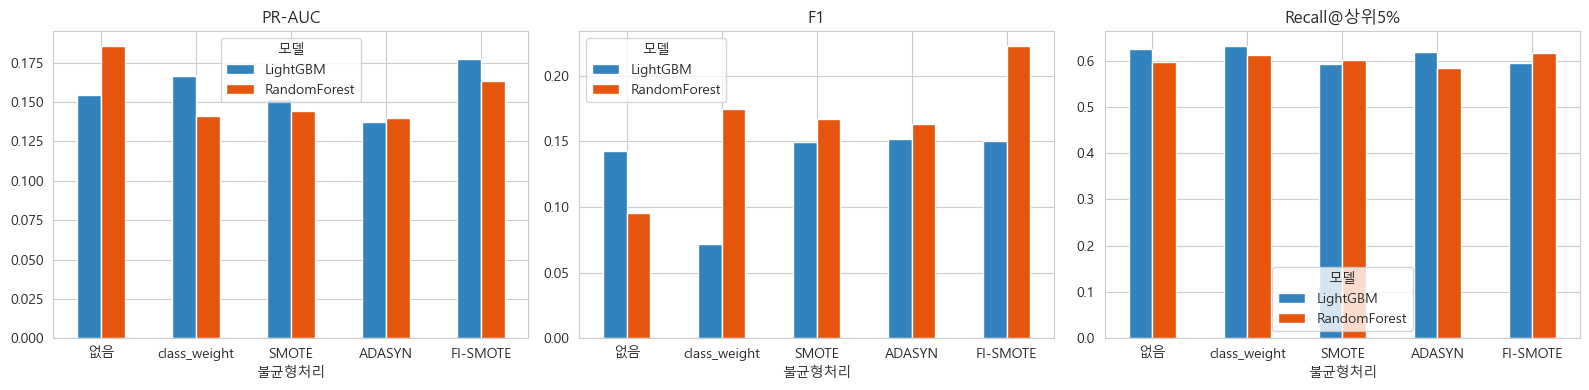

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for i, metric in enumerate(['PR-AUC', 'F1', 'Recall@상위5%']):
    pv = imb_result.pivot(index='불균형처리', columns='모델', values=metric).loc[list(samplers)]
    pv.plot(kind='bar', ax=ax[i], color=['#3182bd', '#e6550d'])
    ax[i].set_title(metric)
    ax[i].tick_params(axis='x', rotation=0)
save('08_imbalance_compare')
plt.show()

**해석**
- 오버샘플링 3종(SMOTE, ADASYN, FI-SMOTE) 중에서는 두 모델 모두 **FI-SMOTE의 PR-AUC가 가장 높다.**
  SMOTE·ADASYN은 오히려 원본(없음)보다 PR-AUC가 떨어졌는데, 무작위 보간이 경계에 노이즈를 만든 것으로 보인다.
- RandomForest + FI-SMOTE는 임계값 0.5에서 **F1(0.22)과 MCC(0.22)가 전체 조합 중 1위**다.
- 다만 순위 지표인 PR-AUC 자체는 오버샘플링을 하지 않은 RandomForest가 가장 높았다.
  오버샘플링의 효과는 주로 "임계값 0.5에서 놓치던 탈퇴 사업장을 더 잡아내는 것(Recall 상승)"에 있다는 뜻이다.
- 이는 FI-SMOTE 논문(극단적 불균형에서 F1·MCC 1위, AUC는 SMOTE 계열과 비슷)과 같은 경향이다.

## 9. 하이퍼파라미터 튜닝: GridSearchCV (9주차)
불균형 처리 비교에서 **F1과 MCC가 가장 높았던 조합은 RandomForest + FI-SMOTE** 였다.
RandomForest의 주요 파라미터를 `scoring='average_precision'`(PR-AUC) 기준 3-겹 교차검증 그리드 서치로 고른다.

In [19]:
from sklearn.model_selection import GridSearchCV
params = {'n_estimators': [100, 200],
          'min_samples_leaf': [1, 3, 5],
          'max_features': ['sqrt', 0.5]}
gs = GridSearchCV(RandomForestClassifier(random_state=42, n_jobs=1), params,
                  scoring='average_precision', cv=StratifiedKFold(3, shuffle=True, random_state=42), n_jobs=-1)
t = time.time()
gs.fit(X_cv, y_cv)
print('탐색 조합 수:', len(gs.cv_results_['params']), f'/ {time.time()-t:.0f}s')
print(gs.best_params_)
print('best PR-AUC (CV):', round(gs.best_score_, 4))

탐색 조합 수: 12 / 649s
{'max_features': 'sqrt', 'min_samples_leaf': 5, 'n_estimators': 200}
best PR-AUC (CV): 0.1807


## 10. 최종 모델 평가
튜닝된 파라미터의 RandomForest를 **FI-SMOTE로 늘린 전체 학습셋**으로 다시 학습하고,
한 번도 보지 않은 테스트셋으로 평가한다.

In [20]:
best_sampler = 'FI-SMOTE'
Xf, yf = fi_smote_resample(X_train, y_train, sampling_strategy=0.1, random_state=42)

final = RandomForestClassifier(random_state=42, n_jobs=-1, **gs.best_params_)
final.fit(Xf, yf)
prob = final.predict_proba(X_test)[:, 1]
final_metrics = evaluate(y_test, prob)
pd.Series(final_metrics).round(4)

PR-AUC         0.1686
ROC-AUC        0.8614
Precision      0.2478
Recall         0.2088
F1             0.2267
MCC            0.2247
Recall@상위5%    0.6290
dtype: float64

### 10-1. 임계값(Threshold) 선택: Precision과 Recall의 트레이드오프 (1주차)
1주차 FDS 예시처럼, 탈퇴 위험 사업장을 **놓치는 비용(FN)** 과 **괜히 점검하는 비용(FP)** 사이에서 기준을 고른다.

F1 최대 임계값 = 0.481 → Precision 0.243, Recall 0.226, F1 0.234


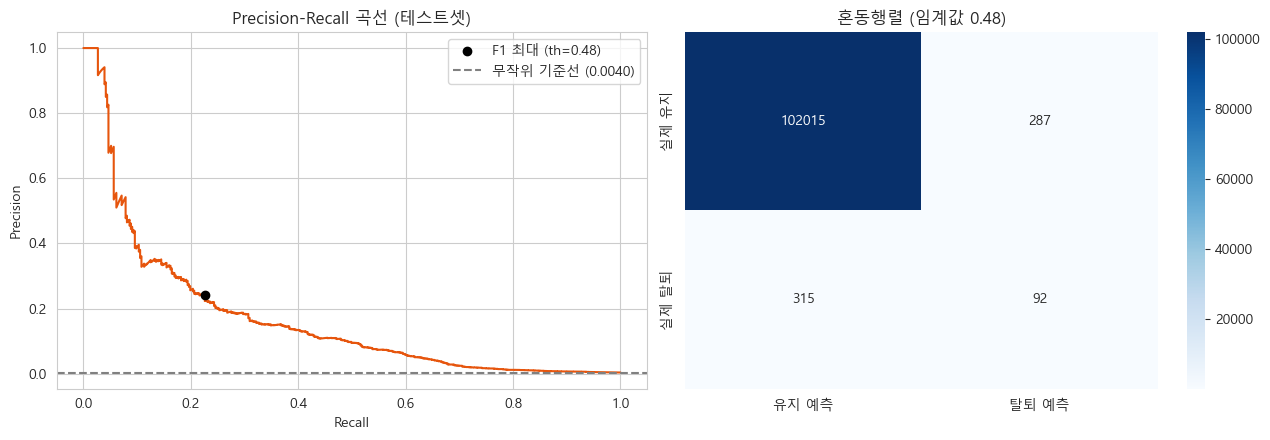

,임계값,Precision,Recall,F1,경보 사업장 수
0,0.500,0.248,0.209,0.227,343
3,0.481,0.243,0.226,0.234,379
1,0.300,0.152,0.366,0.215,982
2,0.200,0.110,0.462,0.177,1713
4,0.100,0.066,0.580,0.119,3565
5,0.050,0.039,0.661,0.073,6929
6,0.020,0.018,0.742,0.035,16608


In [21]:
from sklearn.metrics import precision_recall_curve, confusion_matrix
prec, rec, ths = precision_recall_curve(y_test, prob)
f1s = 2 * prec * rec / (prec + rec + 1e-12)
best_i = np.argmax(f1s[:-1])
best_th = ths[best_i]
print(f'F1 최대 임계값 = {best_th:.3f} → Precision {prec[best_i]:.3f}, Recall {rec[best_i]:.3f}, F1 {f1s[best_i]:.3f}')

table = []
for th in [0.5, 0.3, 0.2, best_th, 0.1, 0.05, 0.02]:
    m = evaluate(y_test, prob, th)
    table.append({'임계값': round(th, 3), 'Precision': m['Precision'], 'Recall': m['Recall'], 'F1': m['F1'],
                  '경보 사업장 수': int((prob >= th).sum())})
th_table = pd.DataFrame(table).drop_duplicates('임계값').sort_values('임계값', ascending=False)
th_table.to_csv('results/threshold_table.csv', index=False, encoding='utf-8-sig')

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(rec, prec, color='#e6550d')
ax[0].scatter(rec[best_i], prec[best_i], color='black', zorder=5, label=f'F1 최대 (th={best_th:.2f})')
ax[0].axhline(y_test.mean(), color='gray', linestyle='--', label=f'무작위 기준선 ({y_test.mean():.4f})')
ax[0].set_xlabel('Recall'); ax[0].set_ylabel('Precision'); ax[0].set_title('Precision-Recall 곡선 (테스트셋)')
ax[0].legend()
cm = confusion_matrix(y_test, (prob >= best_th).astype(int))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax[1],
            xticklabels=['유지 예측', '탈퇴 예측'], yticklabels=['실제 유지', '실제 탈퇴'])
ax[1].set_title(f'혼동행렬 (임계값 {best_th:.2f})')
save('09_pr_curve_cm')
plt.show()
th_table.round(3)

### 10-2. 위험 점수 상위 k% 점검 시 탈퇴 사업장 포착률 (실무 활용 관점)

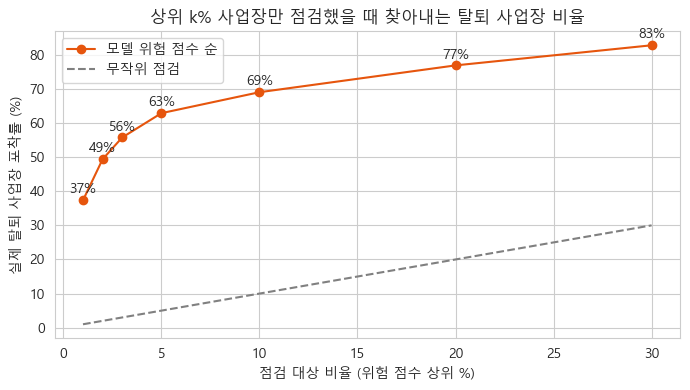

,상위 %,포착률(%),배율(lift)
0,1,37.3,37.3
1,2,49.4,24.7
2,3,55.8,18.6
3,5,62.9,12.6
4,10,69.0,6.9
5,20,76.9,3.8
6,30,82.8,2.8


In [22]:
pcts = [1, 2, 3, 5, 10, 20, 30]
capture = [recall_at_top(y_test, prob, p) * 100 for p in pcts]
plt.figure(figsize=(7, 4))
plt.plot(pcts, capture, marker='o', color='#e6550d', label='모델 위험 점수 순')
plt.plot(pcts, pcts, linestyle='--', color='gray', label='무작위 점검')
for p, c in zip(pcts, capture):
    plt.text(p, c + 2, f'{c:.0f}%', ha='center')
plt.xlabel('점검 대상 비율 (위험 점수 상위 %)'); plt.ylabel('실제 탈퇴 사업장 포착률 (%)')
plt.title('상위 k% 사업장만 점검했을 때 찾아내는 탈퇴 사업장 비율')
plt.legend()
save('10_capture_curve')
plt.show()
pd.DataFrame({'상위 %': pcts, '포착률(%)': np.round(capture, 1), '배율(lift)': np.round(np.array(capture) / pcts, 1)})

## 11. 주요 영향 요인: Feature Importance (7·10주차)

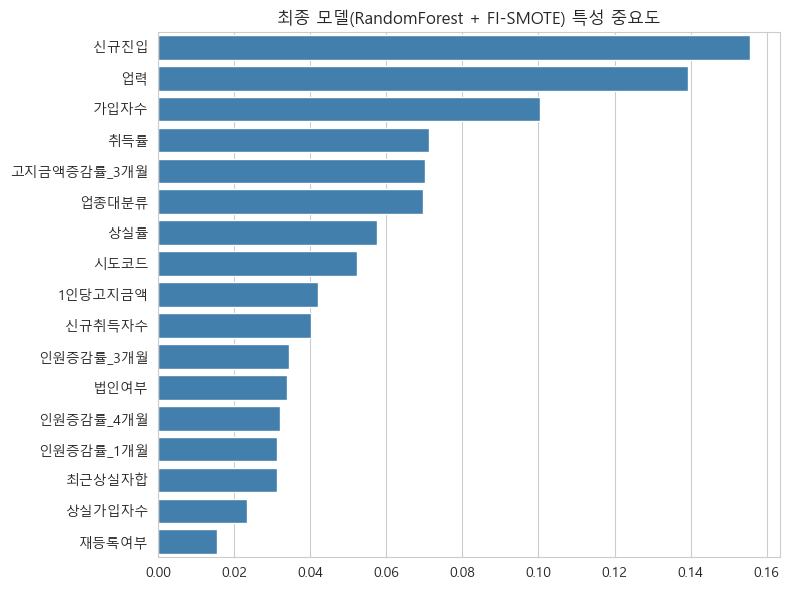

신규진입           0.1557
업력             0.1393
가입자수           0.1003
취득률            0.0712
고지금액증감률_3개월    0.0701
업종대분류          0.0697
상실률            0.0576
시도코드           0.0524
1인당고지금액        0.0420
신규취득자수         0.0401
인원증감률_3개월      0.0344
법인여부           0.0339
인원증감률_4개월      0.0321
인원증감률_1개월      0.0312
최근상실자합         0.0312
상실가입자수         0.0233
재등록여부          0.0156
dtype: float64

In [23]:
fi = pd.Series(final.feature_importances_, index=FEATURES).sort_values(ascending=False)
fi.to_csv('results/feature_importance.csv', encoding='utf-8-sig')

plt.figure(figsize=(8, 6))
sns.barplot(x=fi.values, y=fi.index, color='#3182bd')
plt.title('최종 모델(RandomForest + FI-SMOTE) 특성 중요도')
plt.ylabel('')
save('11_feature_importance')
plt.show()
fi.round(4)

In [24]:
# 상위 변수 3개의 값에 따른 실제 탈퇴율 (중요도의 '방향' 해석)
for col in fi.index[:3]:
    print('■', col)
    if df[col].nunique() <= 2:                       # 0/1 변수는 그대로 비교
        print((df.groupby(col)['탈퇴'].mean() * 100).round(3).to_string(), '\n')
    else:                                            # 연속형은 10분위로 나눠 비교
        q = pd.qcut(df[col].rank(method='first'), 10, labels=[f'{i}분위' for i in range(1, 11)])
        print((df.groupby(q)['탈퇴'].mean() * 100).round(3).to_string(), '\n')

■ 신규진입
신규진입
0    0.251
1    1.312 

■ 업력
업력
1분위     2.255
2분위     0.650
3분위     0.249
4분위     0.214
5분위     0.220
6분위     0.119
7분위     0.084
8분위     0.066
9분위     0.060
10분위    0.041 

■ 가입자수


가입자수
1분위     0.368
2분위     0.939
3분위     0.662
4분위     0.452
5분위     0.315
6분위     0.407
7분위     0.278
8분위     0.249
9분위     0.175
10분위    0.113 



## 12. 결과 저장

In [25]:
summary = pd.Series(final_metrics)
summary['best_threshold'] = best_th
summary['best_sampler'] = best_sampler
summary['n_total'] = len(df)
summary['exit_rate'] = y.mean()
summary.to_csv('results/final_summary.csv', encoding='utf-8-sig')
summary

PR-AUC             0.16859
ROC-AUC           0.861367
Precision         0.247813
Recall            0.208845
F1                0.226667
MCC               0.224679
Recall@상위5%       0.628993
best_threshold    0.480689
best_sampler      FI-SMOTE
n_total             513541
exit_rate         0.003959
dtype: object